# NYC Rideshare · Executive Dashboard

The weekly business review view for the NYC market GM. Change `COMPANY` and `MONTH`
below, then **Run All**.

All numbers come from the gold tables through the shared KPI engine (`metrics/kpi.py`).
`scripts/02_check_consistency.py` proves they match the analyst notebooks and the
embedded ops portal.

*Independent portfolio project using public NYC TLC trip records. Not affiliated with Uber, Lyft or TLC.*

In [1]:
COMPANY = "Uber"        # "Uber" or "Lyft"
MONTH = "2025-03-01"    # any month from 2024-10-01 to 2025-03-01

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import duckdb
import pandas as pd
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+png"   # interactive in VS Code + a static image GitHub can display
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from metrics.kpi import fmt, kpi, kpi_names, kpi_sql

con = duckdb.connect(str(ROOT / "data" / "warehouse.duckdb"), read_only=True)
COLORS = {"Uber": "#1f2937", "Lyft": "#ec4899"}
TEMPLATE = "plotly_white"

names = [n for n in kpi_names() if kpi(n)["type"] != "share_of_total"]
monthly = con.execute(f"""
    select cast(pickup_month as varchar) as month, company,
           {", ".join(f"{kpi_sql(n)} as {n}" for n in names)},
           {kpi_sql('market_share').format(partition='pickup_month')} as market_share
    from gold_monthly_company group by pickup_month, company order by month, company
""").df()
months = sorted(monthly["month"].unique())
prev = months[months.index(MONTH) - 1] if months.index(MONTH) > 0 else None
cur_row = monthly[(monthly.month == MONTH) & (monthly.company == COMPANY)].iloc[0]
prev_row = monthly[(monthly.month == prev) & (monthly.company == COMPANY)].iloc[0] if prev else None

## Scorecard: month vs prior month

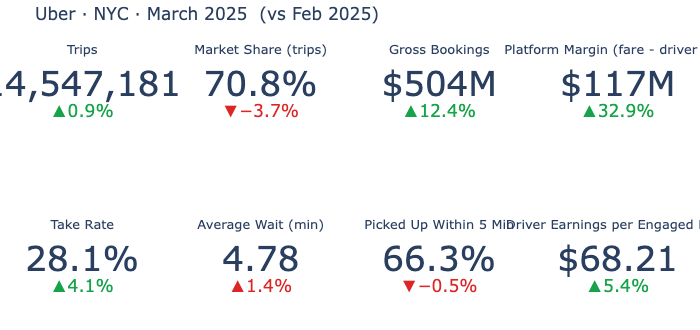

In [3]:
TILES = ["trips", "market_share", "gross_bookings", "platform_margin",
         "take_rate", "avg_wait_min", "pickup_within_5min_rate", "driver_earnings_per_engaged_hour"]
VALUE_FMT = {"int": ",.0f", "usd": "$,.3s", "usd2": "$,.2f", "pct": ".1%", "dec2": ",.2f"}

fig = make_subplots(rows=2, cols=4, specs=[[{"type": "indicator"}] * 4] * 2, vertical_spacing=0.25)
for i, name in enumerate(TILES):
    f = kpi(name)["format"]
    lower_is_better = name == "avg_wait_min"
    fig.add_trace(go.Indicator(
        mode="number+delta",
        value=cur_row[name],
        number={"valueformat": VALUE_FMT[f], "font": {"size": 34}},
        delta=None if prev_row is None else {
            "reference": prev_row[name], "relative": f not in ("pct",), "valueformat": ".1%",
            "increasing": {"color": "#dc2626" if lower_is_better else "#16a34a"},
            "decreasing": {"color": "#16a34a" if lower_is_better else "#dc2626"}},
        title={"text": kpi(name)["label"], "font": {"size": 13}},
    ), row=i // 4 + 1, col=i % 4 + 1)
fig.update_layout(height=330, margin=dict(t=40, b=10, l=10, r=10), template=TEMPLATE,
                  title=f"{COMPANY} · NYC · {pd.Timestamp(MONTH):%B %Y}" + (f"  (vs {pd.Timestamp(prev):%b %Y})" if prev else ""))
fig.show()

## Market share and trips

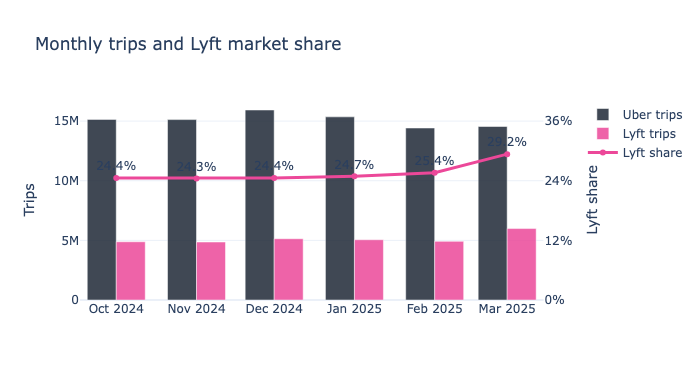

In [4]:
fig = make_subplots(specs=[[{"secondary_y": True}]])
for c in ["Uber", "Lyft"]:
    d = monthly[monthly.company == c]
    fig.add_bar(x=d.month, y=d.trips, name=f"{c} trips", marker_color=COLORS[c], opacity=0.85)
lyft = monthly[monthly.company == "Lyft"]
fig.add_scatter(x=lyft.month, y=lyft.market_share, name="Lyft share", mode="lines+markers+text",
                text=[f"{v:.1%}" for v in lyft.market_share], textposition="top center",
                line=dict(color=COLORS["Lyft"], width=3), secondary_y=True)
fig.update_yaxes(title_text="Trips", secondary_y=False)
fig.update_yaxes(title_text="Lyft share", tickformat=".0%", range=[0, 0.4], secondary_y=True)
fig.update_layout(barmode="group", template=TEMPLATE, height=380, title="Monthly trips and Lyft market share")
fig.show()

## Economics: take rate and driver earnings

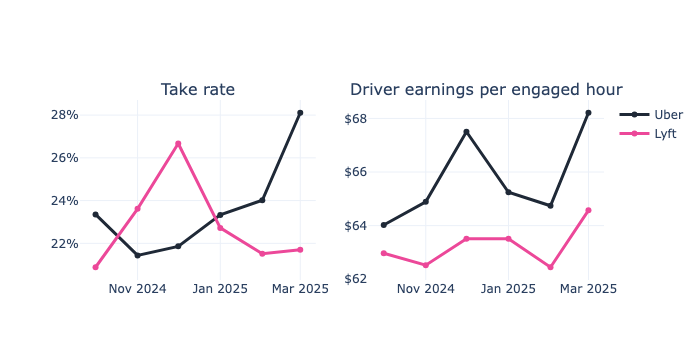

In [5]:
fig = make_subplots(rows=1, cols=2, subplot_titles=("Take rate", "Driver earnings per engaged hour"))
for c in ["Uber", "Lyft"]:
    d = monthly[monthly.company == c]
    fig.add_scatter(x=d.month, y=d.take_rate, name=c, line=dict(color=COLORS[c], width=3), row=1, col=1)
    fig.add_scatter(x=d.month, y=d.driver_earnings_per_engaged_hour, name=c, showlegend=False,
                    line=dict(color=COLORS[c], width=3), row=1, col=2)
fig.update_yaxes(tickformat=".0%", row=1, col=1)
fig.update_yaxes(tickprefix="$", row=1, col=2)
fig.update_layout(template=TEMPLATE, height=360)
fig.show()

## Service quality

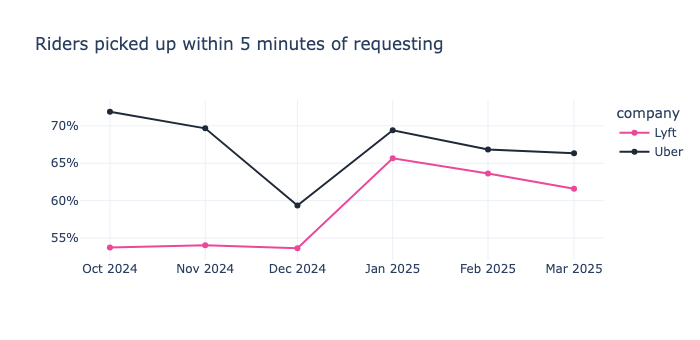

In [6]:
px.line(monthly, x="month", y="pickup_within_5min_rate", color="company", markers=True,
        color_discrete_map=COLORS, template=TEMPLATE, height=340,
        title="Riders picked up within 5 minutes of requesting",
        labels={"pickup_within_5min_rate": "", "month": ""}).update_yaxes(tickformat=".0%").show()

## Where the trips are: pickup zones (selected month)

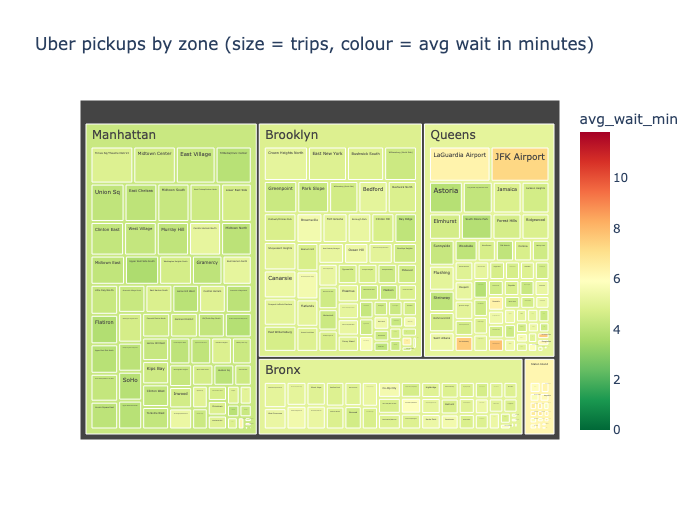

In [7]:
zones = con.execute(f"""
    select z.borough, z.zone, {kpi_sql('trips')} as trips, {kpi_sql('avg_wait_min')} as avg_wait_min,
           {kpi_sql('avg_fare')} as avg_fare
    from gold_daily_zone_company g join dim_zone z on z.zone_id = g.pu_zone_id
    where g.company = '{COMPANY}' and g.pickup_month = date '{MONTH}' and not z.is_unknown
    group by all
""").df()
px.treemap(zones, path=["borough", "zone"], values="trips", color="avg_wait_min",
           color_continuous_scale="RdYlGn_r", height=520, template=TEMPLATE,
           title=f"{COMPANY} pickups by zone (size = trips, colour = avg wait in minutes)").show()

## Congestion pricing (from 5 Jan 2025)

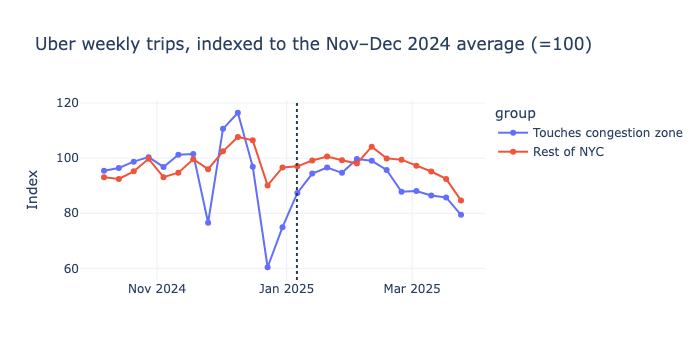

Congestion fee collected on Uber trips, Jan–Mar 2025: $21,705,693


In [8]:
crz = con.execute(f"""
    select pickup_week, company, touches_crz, {kpi_sql('trips')} as trips, {kpi_sql('cbd_fee_revenue')} as fee
    from gold_weekly_crz_company
    where pickup_week between date '2024-10-07' and date '2025-03-24'
    group by all order by pickup_week
""").df()
crz["group"] = crz["touches_crz"].map({True: "Touches congestion zone", False: "Rest of NYC"})
base = crz[crz.pickup_week.astype(str).between("2024-11-04", "2024-12-16")].groupby(["company", "group"])["trips"].mean()
crz["index"] = crz.apply(lambda r: r.trips / base[(r.company, r.group)] * 100, axis=1)
fig = px.line(crz[crz.company == COMPANY], x="pickup_week", y="index", color="group", markers=True, template=TEMPLATE,
              height=360, title=f"{COMPANY} weekly trips, indexed to the Nov–Dec 2024 average (=100)",
              labels={"index": "Index", "pickup_week": ""})
fig.add_vline(x=pd.Timestamp("2025-01-06").timestamp() * 1000, line_dash="dot")
fig.show()
print(f"Congestion fee collected on {COMPANY} trips, Jan–Mar 2025: ${crz[crz.company == COMPANY]['fee'].sum():,.0f}")

## Ops alerts raised for this month

In [9]:
alerts = con.execute(f"""
    select anomaly_type, count(*) as alerts, count(distinct pu_zone_id) as zones
    from gold_zone_hour_scored
    where company = '{COMPANY}' and date_trunc('month', pickup_date) = date '{MONTH}' and anomaly_type is not null
    group by 1
""").df()
alerts

,anomaly_type,alerts,zones
0,drop,604,199
1,surge,1522,230
